# 6. A fair contest: does any tuned model beat the curves?

> **In plain terms.** Nine kinds of model were each given a fair chance: their settings were tuned automatically, on data kept apart from the test. None beat the simple curved model the page already uses, and combining several models didn't help either. The page keeps its model.

Milestones 1 to 3 compared models using mostly default settings, which can be unfair to models that need tuning, such as support vector machines, boosted trees and neural networks. This notebook gives nine model types a properly tuned contest (E12), tests the differences formally (E13), tries combining models into one (E14), and decides whether the published curves model stays.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 6.1 How the contest stays fair

**What we're looking for.** A set-up where tuning can't flatter any model, and every model faces exactly the same test.

In [2]:
from src.data import load_data, FEATURES
from src.modeling import current_features
from src import contest
from src import figures

X, y = load_data()
Xc = X[current_features(FEATURES)]              # the same six inputs for every model
print("Outer splits (scoring):", contest.OUTER_FOLDS, "folds x", contest.OUTER_REPEATS, "repeats")
print("Inner splits (tuning): ", contest.INNER_FOLDS, "folds, inside each outer training set")
print("Tuning trials per model per outer split:", contest.N_TRIALS)
for name, (_, space) in contest.contestants().items():
    print(f"- {name:28s} {'tuned' if space else 'fixed settings'}")

Outer splits (scoring): 5 folds x 3 repeats
Inner splits (tuning):  3 folds, inside each outer training set
Tuning trials per model per outer split: 30
- Curves (M3, as published)    fixed settings
- Curves, tuned                tuned
- Straight lines, tuned        tuned
- k-nearest neighbours         tuned
- Support vector machine       tuned
- Random forest                tuned
- Gradient boosting            tuned
- XGBoost                      tuned
- Neural network               tuned
- Stacked ensemble             fixed settings


**How to read it.** Most models have settings (hyperparameters) that must be chosen, such as how many neighbours to consult or how deep a tree may grow. Tuning means trying many settings and keeping the best. The danger is choosing settings that suit the test women by luck. Nested cross-validation prevents it: the outer splits score each model, and inside each outer training set a second, inner split is used only for tuning. Optuna does the tuning, trying 30 combinations per model per outer split and learning from earlier tries which areas look promising.

**What it means.** Ten contestants face the same 15 outer splits. Two are not tuned: the published curves model, exactly as on the page, and a stacked ensemble whose members use settings fixed in advance. The other eight are tuned, including the curves model itself, so it gets no unfair advantage over the rest.

**What's next and why.** Run the contest. It takes several minutes, so the results are saved and reloaded here.

## 6.2 The league table

**What we're looking for.** Each model's score on women it never saw, with an honest interval around it.

In [3]:
# Reloads reports/m4_contest.json if it exists; pass rerun=True to run all 150 tuned fits again (several minutes).
results = contest.run_contest(Xc, y)
table = contest.league_table(results, Xc, y)
table[["auc", "auc_low", "auc_high", "brier", "auc_45plus", "seconds"]]

,auc,auc_low,auc_high,brier,auc_45plus,seconds
model,,,,,,
"Curves, tuned",0.854,0.817,0.891,0.150,0.790,16.800
"Curves (M3, as published)",0.852,0.812,0.891,0.150,0.787,1.400
Stacked ensemble,0.849,0.811,0.887,0.153,0.778,24.200
Support vector machine,0.840,0.805,0.876,0.157,0.765,18.500
Random forest,0.840,0.802,0.877,0.156,0.761,253.000
"Straight lines, tuned",0.839,0.803,0.874,0.157,0.744,8.400
XGBoost,0.837,0.797,0.877,0.157,0.756,27.500
Neural network,0.835,0.788,0.881,0.158,0.773,38.000
Gradient boosting,0.832,0.792,0.872,0.158,0.755,51.100


**How to read it.** `auc` is the average over the 15 outer splits, with `auc_low` and `auc_high` as its 95% interval. `brier` measures how close the predicted risks are to what happened (lower is better). `auc_45plus` is the AUC among women 45 and over. `seconds` is how long the whole nested run took for that model.

**What it means.** The curves models lead: tuned 0.854, published 0.852. Then the stacked ensemble at 0.849, the support vector machine and random forest at 0.840, straight lines at 0.839, XGBoost 0.837, the neural network 0.835, gradient boosting 0.832 and k-nearest neighbours 0.827. The intervals are wide (about 0.81 to 0.89) and overlap heavily: with 768 women, every model's score is uncertain by several hundredths. The curves models also have the best Brier scores and the best AUC for older women.

**What's next and why.** Overlapping intervals don't settle it, because every model faced the same splits. Compare each one with the published model split by split.

## 6.3 Is anything really better? The corrected test

**What we're looking for.** For each model, the difference from the published model, and whether chance can explain it.

,vs_published,vs_low,vs_high,p_value,wins
model,,,,,
"Curves, tuned",0.002,-0.003,0.007,0.362,0.667
Stacked ensemble,-0.003,-0.009,0.003,0.307,0.267
Support vector machine,-0.011,-0.027,0.004,0.134,0.200
Random forest,-0.012,-0.028,0.004,0.124,0.267
"Straight lines, tuned",-0.013,-0.033,0.006,0.161,0.133
XGBoost,-0.015,-0.033,0.004,0.106,0.200
Neural network,-0.017,-0.047,0.012,0.226,0.200
Gradient boosting,-0.020,-0.042,0.002,0.077,0.067
k-nearest neighbours,-0.025,-0.044,-0.005,0.017,0.067


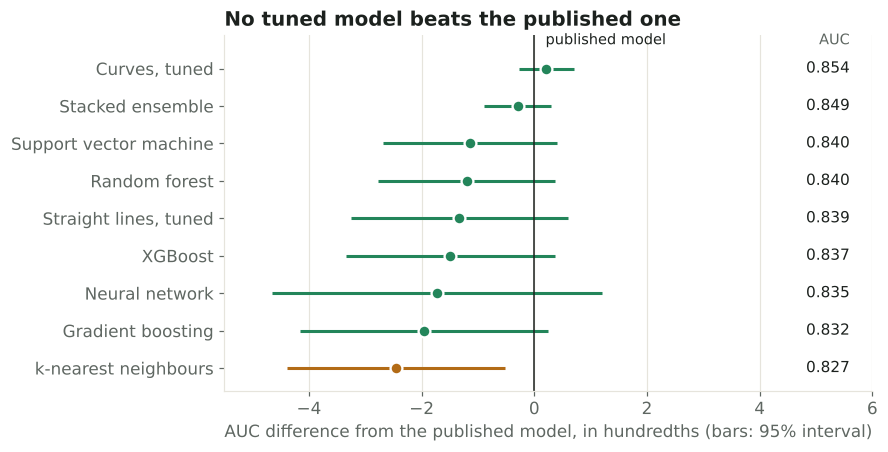

In [4]:
display(table[["vs_published", "vs_low", "vs_high", "p_value", "wins"]].drop(index=contest.PUBLISHED))
figures.m4_contest();

**How to read it.** `vs_published` is the average AUC difference from the published model on the same 15 splits, with its 95% interval (`vs_low` to `vs_high`). `p_value` is the chance of a difference at least this large if the two models were really equal; below 0.05 is the usual bar. `wins` is the share of splits where the model beat the published one. In the chart, a bar that crosses the black line means the difference could be zero.

**What it means.** Nothing beats the published model. The tuned curves model is ahead by 0.002, but its interval runs from -0.003 to +0.007 and p is 0.36: indistinguishable. Every other model is behind, by 0.003 (the ensemble) to 0.025 (k-nearest neighbours). Only k-nearest neighbours is clearly worse (p = 0.02); the rest are probably worse, losing on 73% to 93% of splits, but the test can't rule out chance for any single one of them.

**What's next and why.** The test used here is a corrected one. See why the correction matters, using the earlier claim that curves beat straight lines.

## 6.4 Why the correction matters

**What we're looking for.** The curves-versus-straight-lines comparison from Milestone 3, re-tested with a naive t-test and with the corrected one.

In [5]:
import numpy as np
from scipy import stats
curves, straight = np.array(results[contest.PUBLISHED]["auc"]), np.array(results["Straight lines, tuned"]["auc"])
n_test = len(y) / contest.OUTER_FOLDS
print(f"Curves ahead by {np.mean(curves - straight):.3f} AUC, winning {np.mean(curves > straight):.0%} of splits")
print(f"Naive paired t-test:      p = {stats.ttest_rel(curves, straight).pvalue:.3f}")
print(f"Corrected resampled test: p = {contest.corrected_ttest(curves, straight, len(y) - n_test, n_test)['p']:.3f}")

Curves ahead by 0.013 AUC, winning 87% of splits
Naive paired t-test:      p = 0.006
Corrected resampled test: p = 0.161


**How to read it.** A naive t-test treats the 15 splits as 15 independent experiments. They aren't: each pair of training sets shares most of its women, so the scores move together and look more consistent than they really are. The corrected test (Nadeau and Bengio, 2003) widens the uncertainty to allow for that overlap.

**What it means.** The naive test says the curves' lead over straight lines (0.013, winning 87% of splits) is convincing (p = 0.006). The corrected test says it is suggestive, not proven (p = 0.16). Milestone 3's conclusion stands in direction, with the gain consistent across splits and concentrated in older women, but it is recorded in the findings as likely rather than firm. This is the main reason to use a corrected test: an uncorrected one would have made most of the contest look decisive too.

**What's next and why.** Check whether tuning found stable settings, or wandered.

## 6.5 What did tuning choose?

**What we're looking for.** Whether the best settings are consistent from split to split. Stable choices suggest a real optimum; scattered ones suggest the setting barely matters.

In [6]:
for name in ["Curves, tuned", "Support vector machine", "XGBoost"]:
    print(name)
    display(contest.tuned_settings(results, name).describe().loc[["min", "50%", "max"]])

Curves, tuned


,C,n_knots
min,0.010,3.000
50%,0.043,3.000
max,0.164,4.000


Support vector machine


,C,gamma
min,0.022,0.002
50%,26.276,0.004
max,95.895,0.019


XGBoost


,n,depth,lr,subsample,colsample,min_child,reg_lambda
min,58.000,2.000,0.011,0.608,0.501,1.042,0.123
50%,214.000,2.000,0.020,0.818,0.774,1.861,1.088
max,398.000,5.000,0.105,0.970,0.949,5.822,6.520


**How to read it.** Each table summarises the settings Optuna chose in the 15 outer splits: the smallest, the middle (50%) and the largest. For the curves model, `C` controls smoothing (smaller means smoother curves) and `n_knots` how many places a curve may bend.

**What it means.** The curves model chose stronger smoothing than the published model in every split (C between 0.01 and 0.16, against 0.3 on the page), and 3 bend points rather than 4 in 9 of the 15 splits. In other words, slightly smoother curves are preferred, which fits the suspicion that BMI's flat stretch is noise. The support vector machine's C ranged from 0.02 to 96, meaning its score barely depends on it. XGBoost almost always chose depth 2, very shallow trees, which behave much like adding up one effect per input: the same structure as the curves model.

**What's next and why.** See whether combining model types helps.

## 6.6 Does combining models help? (E14)

**What we're looking for.** Whether a stacked ensemble, which blends four different model types, beats its best member.

In [7]:
from src.contest import stacked_ensemble
print("Members:", ", ".join(name for name, _ in stacked_ensemble().estimators), "| combined by: logistic regression")
table.loc[[contest.PUBLISHED, "Stacked ensemble"], ["auc", "brier", "auc_45plus", "vs_published", "p_value"]]

Members: curves, svm, forest, boosting | combined by: logistic regression


,auc,brier,auc_45plus,vs_published,p_value
model,,,,,
"Curves (M3, as published)",0.852,0.150,0.787,0.000,1.000
Stacked ensemble,0.849,0.153,0.778,-0.003,0.307


**How to read it.** Stacking trains four models (the curves model, a support vector machine, a random forest and gradient boosting), then a final logistic regression learns how much to trust each one's risk. The final step learns from predictions the members made on data they hadn't seen, so it isn't fooled by their over-confidence.

**What it means.** The ensemble scores 0.849, slightly below the curves model alone (0.852), with a worse Brier score. Blending only helps when the members get different women wrong; here they mostly agree, and the weaker members dilute the best one. It also takes 17 times longer to run and is far harder to explain.

**What's next and why.** Make the decision.

## 6.7 Decision: keep the published model

**What we're looking for.** The case for and against changing the page's model.

In [8]:
table.loc[[contest.PUBLISHED, "Curves, tuned", "Stacked ensemble", "Support vector machine"],
          ["auc", "auc_low", "auc_high", "brier", "auc_45plus", "vs_published", "p_value"]]

,auc,auc_low,auc_high,brier,auc_45plus,vs_published,p_value
model,,,,,,,
"Curves (M3, as published)",0.852,0.812,0.891,0.150,0.787,0.000,1.000
"Curves, tuned",0.854,0.817,0.891,0.150,0.790,0.002,0.362
Stacked ensemble,0.849,0.811,0.887,0.153,0.778,-0.003,0.307
Support vector machine,0.840,0.805,0.876,0.157,0.765,-0.011,0.134


**How to read it.** The published model against the three closest rivals, on every measure the contest produced.

**What it means.** Decision D14: the page keeps the curves model from Milestone 3. The tuned version's 0.002 gain is within noise, and switching would change every number on the page for no real improvement. The preference for smoother curves is noted for Milestone 6, which looks at what the model does with each input. The bigger lesson is about the data: on 768 women and six inputs, every reasonable method lands between 0.83 and 0.85. The ceiling is set by the information in the measurements, not by the choice of algorithm.

**What's next and why.** Milestone 5 turns from ranking to deciding: where the cut-off should go once the costs of missed cases and false alarms are stated, and whether different age groups need different cut-offs (B12).